# FL-M5 T10: LP router vs greedy (D2)

Which backend should serve each request class (extraction, short Q&A, long synthesis): the vLLM
student (GPTQ, laptop GPU), the GGUF student (llama.cpp, CPU) or Gemini 3.1 Flash-Lite (free tier)?

- **Rule:** `bench/m5_router_rule.json`, committed in `e75365e` before the router existed: scenarios,
  traffic, latency limits, accuracy floors, the greedy baseline and what to report.
- **Inputs:** `bench/router_inputs.json` (`dc5e101`), dev split only, every value sourced; checked
  here against the SHA-256 the rule pins.
- **Logic:** `src/filinglens/serve/router.py` (LP, `scipy.optimize.linprog`, HiGHS) and
  `src/filinglens/serve/greedy.py` (greedy baseline, hand-written). This notebook only reads,
  re-solves to check the committed results, and draws.
- **Cost:** list prices for Gemini and electricity for the local backends. **Actual spend is $0**
  (Gemini free tier, no billing linked; local backends on the author's laptop).

Re-run: `uv run python -m filinglens.serve.router`, then execute this notebook.

In [1]:
import json
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import matplotlib
import matplotlib.transforms

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

from filinglens.serve import router

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
rule, inputs = router.load_rule_and_inputs()  # refuses inputs whose sha256 isn't the pinned one
results = json.loads(Path("bench/router_results.json").read_text())
assert results["inputs"]["sha256"] == rule["inputs"]["sha256"]
print("rule:", rule["rule"])
print("inputs sha256:", rule["inputs"]["sha256"])
print("spend:", inputs["spend"])

rule: FL-M5 T10 router: pre-registered before serve/router.py exists or any route is solved
inputs sha256: 7e1dcf21501a1f7eda91005851494c62083aa2e897fd3e9998b8652c4a68295f
spend: {'actual_usd': 0, 'why': "Gemini free tier (no billing linked); local backends on the author's laptop", 'modelled': 'list prices (Gemini) and electricity at the EIA US average (local)'}


## 1. Inputs (dev measurements, list prices)

Accuracy is category macro-F1 for extraction and token-F1 against synthetic Qwen3-4B answers for
short Q&A; long synthesis has no accuracy, only context eligibility (16,384 tokens). Costs are per
1,000 requests. Local costs are electricity only (vLLM: measured GPU board power; GGUF: a 75 W CPU
estimate), so they are lower bounds.

In [2]:
rows = []
for b, spec in inputs["backends"].items():
    for cls in ("extraction", "short_qa"):
        m = spec[cls]
        rows.append(
            {
                "backend": b,
                "class": cls,
                "accuracy": m["accuracy"],
                "accuracy_ci95": m["accuracy_ci95"],
                "p95_s": m["latency_p95_s"],
                "mean_s": m["latency_mean_s"],
                "error_rate": m["error_rate"],
                "usd_per_1k": m["usd_per_1k_requests"],
            }
        )
    ls = spec["long_synthesis"]
    rows.append(
        {
            "backend": b,
            "class": "long_synthesis",
            "accuracy": None,
            "accuracy_ci95": None,
            "p95_s": None,
            "mean_s": None,
            "error_rate": None,
            "usd_per_1k": ls.get("usd_per_request_nominal", float("nan")) * 1000
            if ls["eligible"]
            else None,
        }
    )
inputs_table = pd.DataFrame(rows)
inputs_table

,backend,class,accuracy,accuracy_ci95,p95_s,mean_s,error_rate,usd_per_1k
0,vllm,extraction,0.7273,"[0.514, 0.807]",0.5269,0.4369,0.0000,0.001413
1,vllm,short_qa,0.5481,"[0.5145, 0.5824]",0.3248,0.2057,0.0000,0.000665
2,vllm,long_synthesis,NaN,None,NaN,NaN,NaN,NaN
3,gguf,extraction,0.6915,"[0.473, 0.767]",4.8413,3.3491,0.0000,0.012678
4,gguf,short_qa,0.5385,"[0.5051, 0.5733]",1.8064,1.2599,0.0000,0.004769
5,gguf,long_synthesis,NaN,None,NaN,NaN,NaN,NaN
6,gemini,extraction,0.7175,"[0.523, 0.785]",35.8576,6.2258,0.0000,0.554375
7,gemini,short_qa,0.4994,"[0.4646, 0.5332]",20.3861,3.8948,0.0055,0.139750
8,gemini,long_synthesis,NaN,None,NaN,NaN,NaN,4.596000


## 2. Constraints

Eligibility first (not in the LP): a backend takes a class only if its p95 is within the class's
limit (short Q&A 5 s, extraction 60 s, long synthesis none) and, for long synthesis, its context
holds 16,384 tokens. p95 can't enter the LP: the tail of a traffic mix is not the share-weighted
mean of the tails.

LP over the shares `x[class/backend]` (each class's shares sum to 1): minimize
`sum x * traffic * usd_per_request` subject to the rows below (`A x <= b`). Floors appear negated
(`-sum x * accuracy <= -floor`).

In [3]:
problems = {}
for scenario in rule["scenarios"]:
    p = router.build_problem(rule, inputs, scenario, rule["traffic_per_day"]["main"])
    problems[scenario] = p
    rows_ = router.inequality_rows(p)
    cols = [f"{o.cls}/{o.backend}" for o in p.options]
    table = pd.DataFrame(rows_.a, index=rows_.names, columns=cols)
    table["<= bound"] = rows_.b
    print(f"\n{scenario}: traffic/day {p.traffic}")
    print(f"floors (best eligible dev accuracy - 0.01): {p.floors}")
    print("eligible:", cols)
    display(table.round(6))


S1_gpu_on: traffic/day {'extraction': 500.0, 'short_qa': 200.0, 'long_synthesis': 50.0}
floors (best eligible dev accuracy - 0.01): {'extraction': 0.7172999999999999, 'short_qa': 0.5381, 'long_synthesis': None}
eligible: ['extraction/vllm', 'extraction/gguf', 'extraction/gemini', 'short_qa/vllm', 'short_qa/gguf', 'long_synthesis/gemini']


,extraction/vllm,extraction/gguf,extraction/gemini,short_qa/vllm,short_qa/gguf,long_synthesis/gemini,<= bound
floor:extraction,-0.7273,-0.6915,-0.717500,0.0000,0.0000,0.000000,-0.7173
floor:short_qa,0.0000,0.0000,0.000000,-0.5481,-0.5385,0.000000,-0.5381
gemini_rpd,0.0000,0.0000,500.000000,0.0000,0.0000,50.000000,500.0000
gemini_rpm,0.0000,0.0000,0.347222,0.0000,0.0000,0.034722,15.0000
gemini_tpm,0.0000,0.0000,604.548611,0.0000,0.0000,555.000000,250000.0000
busy:vllm,218.4500,0.0000,0.000000,41.1400,0.0000,0.000000,86400.0000
busy:gguf,0.0000,1674.5500,0.000000,0.0000,251.9800,0.000000,86400.0000



S2_gpu_off: traffic/day {'extraction': 500.0, 'short_qa': 200.0, 'long_synthesis': 50.0}
floors (best eligible dev accuracy - 0.01): {'extraction': 0.7075, 'short_qa': 0.5285, 'long_synthesis': None}
eligible: ['extraction/gguf', 'extraction/gemini', 'short_qa/gguf', 'long_synthesis/gemini']


,extraction/gguf,extraction/gemini,short_qa/gguf,long_synthesis/gemini,<= bound
floor:extraction,-0.6915,-0.717500,0.0000,0.000000,-0.7075
floor:short_qa,0.0000,0.000000,-0.5385,0.000000,-0.5285
gemini_rpd,0.0000,500.000000,0.0000,50.000000,500.0000
gemini_rpm,0.0000,0.347222,0.0000,0.034722,15.0000
gemini_tpm,0.0000,604.548611,0.0000,555.000000,250000.0000
busy:gguf,1674.5500,0.000000,251.9800,0.000000,86400.0000


## 3. Solutions: LP vs greedy (traffic 500 / 200 / 50 per day)

The committed results are re-solved here; the check below fails if they don't reproduce.
A dual is the change in the LP's $/day per unit of a row's bound: for a floor row it's per 1.0 of
accuracy, so multiply by 0.01 for the cost of raising that floor by 0.01.

In [4]:
for key, r in results["results"].items():
    scenario, case = key.split("/")
    p = router.build_problem(rule, inputs, scenario, rule["traffic_per_day"][case])
    lp, g = router.solve_lp(p), router.run_greedy(p)
    assert lp["status"] == r["lp"]["status"] and g["status"] == r["greedy"]["status"]
    if lp["status"] == "optimal":
        assert abs(lp["cost_usd_per_day"] - r["lp"]["cost_usd_per_day"]) < 1e-12
print("committed results reproduce")


def solution_table(r: dict) -> pd.DataFrame:
    keys = sorted(set(r["lp"].get("requests") or {}) | set(r["greedy"]["requests"]))
    return pd.DataFrame(
        {
            "lp_requests": [(r["lp"].get("requests") or {}).get(k, 0.0) for k in keys],
            "greedy_requests": [r["greedy"]["requests"].get(k, 0.0) for k in keys],
        },
        index=keys,
    ).round(2)


for key, r in results["results"].items():
    if not key.endswith("/main"):
        continue
    print(f"\n{key}")
    display(solution_table(r))
    lp, g = r["lp"], r["greedy"]
    print(
        f"LP: {lp['status']}, ${lp.get('cost_usd_per_day', float('nan')):.6f}/day, "
        f"binding {lp.get('binding')}"
    )
    nonzero = {k: round(v, 6) for k, v in (lp.get("duals_usd_per_unit") or {}).items() if v}
    print(f"    duals (change in $/day per unit of bound): {nonzero}")
    print(
        f"greedy: {g['status']}, ${g['cost_usd_per_day']:.6f}/day, unrouted {g['unrouted']}, "
        f"breaks LP rows: {g['violates_lp_rows']}"
    )

committed results reproduce

S1_gpu_on/main


,lp_requests,greedy_requests
extraction/gemini,0.0,0.0
extraction/gguf,0.0,0.0
extraction/vllm,500.0,500.0
long_synthesis/gemini,50.0,50.0
short_qa/gguf,0.0,0.0
short_qa/vllm,200.0,200.0


LP: optimal, $0.230640/day, binding []
    duals (change in $/day per unit of bound): {}
greedy: all routed, $0.230640/day, unrouted {'extraction': 0.0, 'short_qa': 0.0, 'long_synthesis': 0.0}, breaks LP rows: []

S2_gpu_off/main


,lp_requests,greedy_requests
extraction/gemini,307.69,500.0
extraction/gguf,192.31,0.0
long_synthesis/gemini,50.00,0.0
short_qa/gguf,200.00,200.0


LP: optimal, $0.403769/day, binding ['floor:extraction']
    duals (change in $/day per unit of bound): {'floor:extraction': -10.417255}
greedy: unrouted, $0.278141/day, unrouted {'extraction': 0.0, 'short_qa': 0.0, 'long_synthesis': 50.0}, breaks LP rows: []


## 4. Savings vs greedy on the same traffic mix

Per the rule: savings = greedy cost - LP cost when both route all traffic; if greedy leaves
traffic unrouted, savings are undefined and the result is which one can route the mix.

In [5]:
summary = pd.DataFrame(
    [
        {
            "run": key,
            "lp_status": r["lp"]["status"],
            "lp_usd_per_day": r["lp"].get("cost_usd_per_day"),
            "greedy_status": r["greedy"]["status"],
            "greedy_usd_per_day": r["greedy"]["cost_usd_per_day"],
            "greedy_unrouted": sum(r["greedy"]["unrouted"].values()),
            "result": r["comparison"],
        }
        for key, r in results["results"].items()
    ]
)
summary

,run,lp_status,lp_usd_per_day,greedy_status,greedy_usd_per_day,greedy_unrouted,result
0,S1_gpu_on/main,optimal,0.230640,all routed,0.230640,0.0,"{'savings_usd_per_day': 0.0, 'savings_pct': 0.0}"
1,S1_gpu_on/infeasible_case,infeasible,NaN,unrouted,2.298840,100.0,"{'savings': None, 'note': 'LP infeasible; gree..."
2,S2_gpu_off/main,optimal,0.403769,unrouted,0.278141,50.0,"{'savings': None, 'note': 'greedy leaves 50 re..."
3,S2_gpu_off/infeasible_case,infeasible,NaN,unrouted,0.278141,600.0,"{'savings': None, 'note': 'LP infeasible; gree..."


## 5. Floor sweep: is there any floor where the LP saves money?

The headline floors come from a rule (best eligible accuracy - 0.01). The sweep moves the
extraction floor from the lowest to the highest eligible accuracy (step 0.0025), other floors as
in the rule. Costs are compared only where a method routes all traffic; points where greedy leaves
traffic unrouted, or the LP is infeasible, are marked along the bottom instead (a method that serves
less traffic isn't cheaper, it's failing).

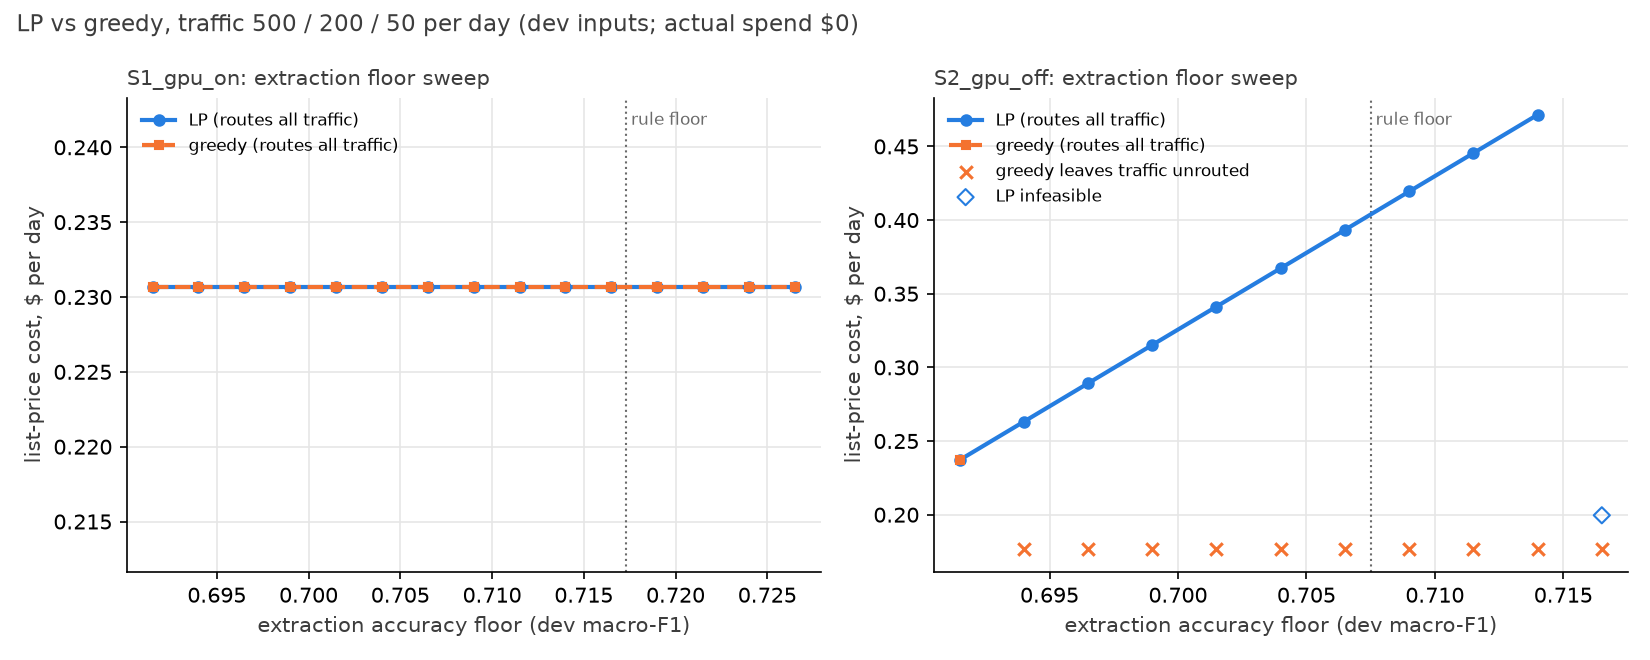

In [6]:
BLUE, ORANGE, INK, MUTED, GRID = "#257de0", "#f47230", "#3d3d3d", "#6b6b6b", "#e6e6e6"
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, scenario in zip(axes, rule["scenarios"], strict=True):
    pts = results["results"][f"{scenario}/main"]["sweep"]["extraction"]
    lp_ok = [q for q in pts if q["lp_status"] == "optimal"]
    lp_bad = [q for q in pts if q["lp_status"] != "optimal"]
    g_ok = [q for q in pts if q["greedy_unrouted"] <= 1e-6]
    g_bad = [q for q in pts if q["greedy_unrouted"] > 1e-6]
    ax.plot(
        [q["floor"] for q in lp_ok],
        [q["lp_cost_usd_per_day"] for q in lp_ok],
        color=BLUE,
        lw=2,
        marker="o",
        ms=5,
        label="LP (routes all traffic)",
        zorder=3,
    )
    if g_ok:
        ax.plot(
            [q["floor"] for q in g_ok],
            [q["greedy_cost_usd_per_day"] for q in g_ok],
            color=ORANGE,
            lw=2,
            ls="--",
            marker="s",
            ms=4,
            label="greedy (routes all traffic)",
            zorder=4,
        )
    strip = matplotlib.transforms.blended_transform_factory(ax.transData, ax.transAxes)
    if g_bad:
        ax.scatter(
            [q["floor"] for q in g_bad],
            [0.05] * len(g_bad),
            transform=strip,
            marker="x",
            s=36,
            color=ORANGE,
            label="greedy leaves traffic unrouted",
        )
    if lp_bad:
        ax.scatter(
            [q["floor"] for q in lp_bad],
            [0.12] * len(lp_bad),
            transform=strip,
            marker="D",
            s=30,
            facecolor="none",
            edgecolor=BLUE,
            label="LP infeasible",
        )
    floors_all = [q["floor"] for q in pts]
    pad = 0.04 * (max(floors_all) - min(floors_all))
    ax.set_xlim(min(floors_all) - pad, max(floors_all) + pad)  # strip markers don't autoscale
    rule_floor = problems[scenario].floors["extraction"]
    ax.axvline(rule_floor, color=MUTED, lw=1, ls=":")
    ax.text(rule_floor, 0.97, " rule floor", transform=strip, fontsize=8, color=MUTED, va="top")
    ax.set_title(f"{scenario}: extraction floor sweep", fontsize=10, color=INK, loc="left")
    ax.set_xlabel("extraction accuracy floor (dev macro-F1)", color=INK)
    ax.set_ylabel("list-price cost, $ per day", color=INK)
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    lo, hi = ax.get_ylim()
    ax.set_ylim(lo - 0.25 * (hi - lo), hi)  # room for the marker strip at the bottom
    ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.suptitle(
    "LP vs greedy, traffic 500 / 200 / 50 per day (dev inputs; actual spend $0)",
    fontsize=11,
    color=INK,
    x=0.01,
    ha="left",
)
fig.tight_layout()
fig.savefig("bench/router_sweep.png", dpi=150)
plt.close(fig)
display(Image("bench/router_sweep.png"))

In [7]:
sweep_rows = []
for scenario in rule["scenarios"]:
    for cls, pts in results["results"][f"{scenario}/main"]["sweep"].items():
        for q in pts:
            sweep_rows.append({"scenario": scenario, "class": cls, **q})
sweep_table = pd.DataFrame(sweep_rows)
both = sweep_table[(sweep_table.lp_status == "optimal") & (sweep_table.greedy_unrouted <= 1e-6)]
saving = both.greedy_cost_usd_per_day - both.lp_cost_usd_per_day
print(
    f"sweep points: {len(sweep_table)}; both route all: {len(both)}; "
    f"max saving there: ${saving.max() if len(saving) else float('nan'):.6g}/day"
)
print(
    f"points where greedy leaves traffic unrouted and the LP routes all: "
    f"{int(((sweep_table.lp_status == 'optimal') & (sweep_table.greedy_unrouted > 1e-6)).sum())}"
)
sweep_table

sweep points: 31; both route all: 20; max saving there: $0/day
points where greedy leaves traffic unrouted and the LP routes all: 9


,scenario,class,floor,lp_status,lp_cost_usd_per_day,greedy_status,greedy_cost_usd_per_day,greedy_unrouted
0,S1_gpu_on,extraction,0.6915,optimal,0.230640,all routed,0.230640,0.0
1,S1_gpu_on,extraction,0.6940,optimal,0.230640,all routed,0.230640,0.0
2,S1_gpu_on,extraction,0.6965,optimal,0.230640,all routed,0.230640,0.0
3,S1_gpu_on,extraction,0.6990,optimal,0.230640,all routed,0.230640,0.0
4,S1_gpu_on,extraction,0.7015,optimal,0.230640,all routed,0.230640,0.0
5,S1_gpu_on,extraction,0.7040,optimal,0.230640,all routed,0.230640,0.0
6,S1_gpu_on,extraction,0.7065,optimal,0.230640,all routed,0.230640,0.0
7,S1_gpu_on,extraction,0.7090,optimal,0.230640,all routed,0.230640,0.0
8,S1_gpu_on,extraction,0.7115,optimal,0.230640,all routed,0.230640,0.0
9,S1_gpu_on,extraction,0.7140,optimal,0.230640,all routed,0.230640,0.0


## 6. Infeasible case: long synthesis at 600 per day

Long synthesis is Gemini-only (context), and Gemini's free tier allows 500 requests per day.
`diagnose_infeasible` drops one constraint at a time; the ones whose removal alone makes the LP
feasible are reported.

In [8]:
for key, r in results["results"].items():
    if key.endswith("/infeasible_case"):
        print(
            f"{key}: LP {r['lp']['status']}; infeasible because of {r.get('infeasible_because')};"
            f" greedy unrouted {r['greedy']['unrouted']}"
        )

S1_gpu_on/infeasible_case: LP infeasible; infeasible because of ['gemini_rpd']; greedy unrouted {'extraction': 0.0, 'short_qa': 0.0, 'long_synthesis': 100.0}
S2_gpu_off/infeasible_case: LP infeasible; infeasible because of ['gemini_rpd']; greedy unrouted {'extraction': 0.0, 'short_qa': 0.0, 'long_synthesis': 600.0}


## Limits

- Accuracy differences between backends are within their 95% CIs on the dev split (71 and 182
  items); the LP treats point estimates as exact.
- Short-Q&A accuracy is agreement with synthetic Qwen3-4B answers, not correctness.
- Gemini latency and failures (p95 20-36 s, 1 / 182 HTTP 503, two 429s) come from one day on the
  free tier; long-synthesis accuracy and latency are not measured.
- Local costs are electricity only, at the US average residential price; hardware and the rest of
  the laptop are left out. GGUF's power is an estimate.
- Traffic is a stated scenario, spread evenly over the day; bursts would make the per-minute limits
  matter.